### Load Libraries and Dataset


In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings

warnings.filterwarnings('ignore')

# Read dataset
ipl_data = pd.read_csv('IPL.csv')
ipl_data.head()


,match_id,date,venue,team1,team2,stage,toss_winner,toss_decision,first_ings_score,first_ings_wkts,second_ings_score,second_ings_wkts,match_winner,won_by,margin,player_of_the_match,top_scorer,highscore,best_bowling,best_bowling_figure
0,1,"March 26,2022","Wankhede Stadium, Mumbai",Chennai,Kolkata,Group,Kolkata,Field,131,5,133,4,Kolkata,Wickets,6,Umesh Yadav,MS Dhoni,50,Dwayne Bravo,3--20
1,2,"March 27,2022","Brabourne Stadium, Mumbai",Delhi,Mumbai,Group,Delhi,Field,177,5,179,6,Delhi,Wickets,4,Kuldeep Yadav,Ishan Kishan,81,Kuldeep Yadav,3--18
2,3,"March 27,2022","Dr DY Patil Sports Academy, Mumbai",Banglore,Punjab,Group,Punjab,Field,205,2,208,5,Punjab,Wickets,5,Odean Smith,Faf du Plessis,88,Mohammed Siraj,2--59
3,4,"March 28,2022","Wankhede Stadium, Mumbai",Gujarat,Lucknow,Group,Gujarat,Field,158,6,161,5,Gujarat,Wickets,5,Mohammed Shami,Deepak Hooda,55,Mohammed Shami,3--25
4,5,"March 29,2022","Maharashtra Cricket Association Stadium,Pune",Hyderabad,Rajasthan,Group,Hyderabad,Field,210,6,149,7,Rajasthan,Runs,61,Sanju Samson,Aiden Markram,57,Yuzvendra Chahal,3--22


### Basic Dataset Information


In [2]:
# Check dataset shape and missing values
print(f"Rows: {ipl_data.shape[0]}, Columns: {ipl_data.shape[1]}")
ipl_data.info()
ipl_data.isnull().sum()


Rows: 74, Columns: 20
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 74 entries, 0 to 73
Data columns (total 20 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   match_id             74 non-null     int64 
 1   date                 74 non-null     object
 2   venue                74 non-null     object
 3   team1                74 non-null     object
 4   team2                74 non-null     object
 5   stage                74 non-null     object
 6   toss_winner          74 non-null     object
 7   toss_decision        74 non-null     object
 8   first_ings_score     74 non-null     int64 
 9   first_ings_wkts      74 non-null     int64 
 10  second_ings_score    74 non-null     int64 
 11  second_ings_wkts     74 non-null     int64 
 12  match_winner         74 non-null     object
 13  won_by               74 non-null     object
 14  margin               74 non-null     int64 
 15  player_of_the_match  74 non-null     

match_id               0
date                   0
venue                  0
team1                  0
team2                  0
stage                  0
toss_winner            0
toss_decision          0
first_ings_score       0
first_ings_wkts        0
second_ings_score      0
second_ings_wkts       0
match_winner           0
won_by                 0
margin                 0
player_of_the_match    0
top_scorer             0
highscore              0
best_bowling           0
best_bowling_figure    0
dtype: int64

### 1. Which team won the most matches?


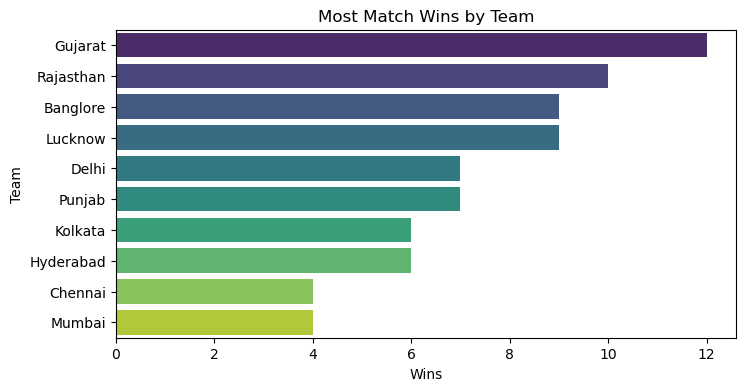

In [3]:
# Count wins by team
win_counts = ipl_data['match_winner'].value_counts()

plt.figure(figsize=(8, 4))
sns.barplot(x=win_counts.values, y=win_counts.index, palette='viridis')
plt.title("Most Match Wins by Team")
plt.xlabel("Wins")
plt.ylabel("Team")
plt.show()


### 2. Toss Decision Trends


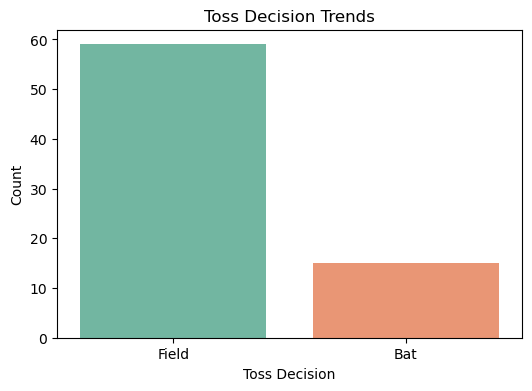

In [4]:
# Toss decision count
toss_decision_data = ipl_data['toss_decision'].value_counts()

plt.figure(figsize=(6, 4))
sns.countplot(x=ipl_data['toss_decision'], palette='Set2')
plt.title("Toss Decision Trends")
plt.xlabel("Toss Decision")
plt.ylabel("Count")
plt.show()


### 3. Toss Decision Share (Pie Chart)


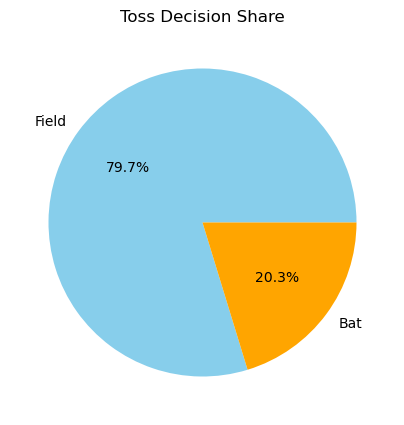

In [5]:
# Pie chart of toss decision
plt.figure(figsize=(5, 5))
plt.pie(toss_decision_data.values, labels=toss_decision_data.index, autopct='%1.1f%%', colors=['skyblue', 'orange'])
plt.title("Toss Decision Share")
plt.show()


### 4. Toss Winner vs Match Winner Percentage


In [6]:
# Calculate percentage of toss winners winning the match
toss_and_match_win = ipl_data[ipl_data['toss_winner'] == ipl_data['match_winner']]['match_id'].count()
win_percentage = (toss_and_match_win * 100) / ipl_data.shape[0]
print(f"Toss winner also won the match: {win_percentage:.2f}%")


Toss winner also won the match: 48.65%


### 5. How do teams win? (Won by Runs vs Wickets)


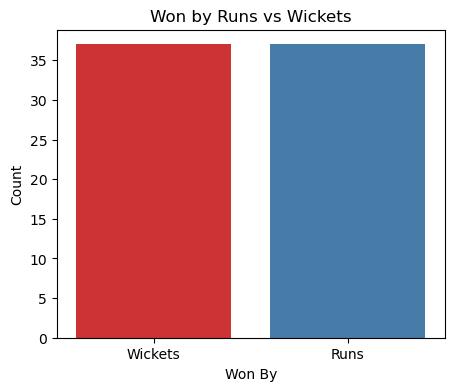

In [7]:
# Matches won by runs or wickets
outcome_counts = ipl_data['won_by'].value_counts()

plt.figure(figsize=(5, 4))
sns.countplot(x=ipl_data['won_by'], palette='Set1')
plt.title("Won by Runs vs Wickets")
plt.xlabel("Won By")
plt.ylabel("Count")
plt.show()


### 6. Distribution of Winning Margins


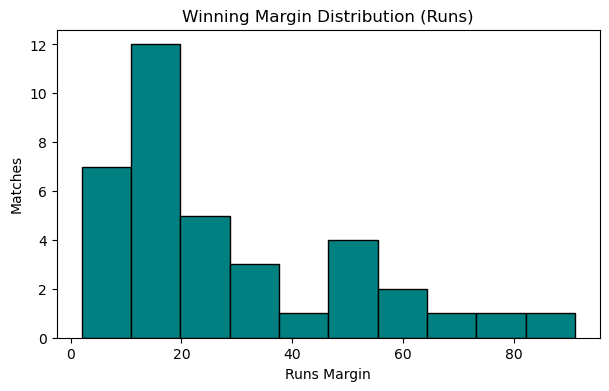

In [8]:
# Histogram of winning margins by runs
margin_runs = ipl_data[ipl_data['won_by'] == 'Runs']['margin']

plt.figure(figsize=(7, 4))
plt.hist(margin_runs, bins=10, color='teal', edgecolor='black')
plt.title("Winning Margin Distribution (Runs)")
plt.xlabel("Runs Margin")
plt.ylabel("Matches")
plt.show()


### 7. Most Player of the Match Awards


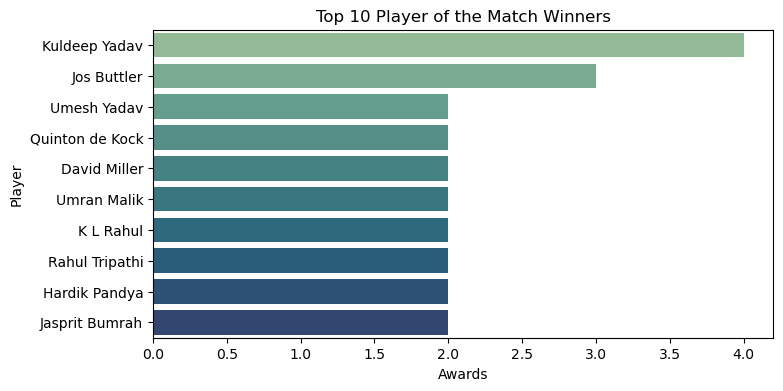

In [9]:
# Top 10 player of the match winners
potm_counts = ipl_data['player_of_the_match'].value_counts().head(10)

plt.figure(figsize=(8, 4))
sns.barplot(x=potm_counts.values, y=potm_counts.index, palette='crest')
plt.title("Top 10 Player of the Match Winners")
plt.xlabel("Awards")
plt.ylabel("Player")
plt.show()


### 8. Top Scorer Players


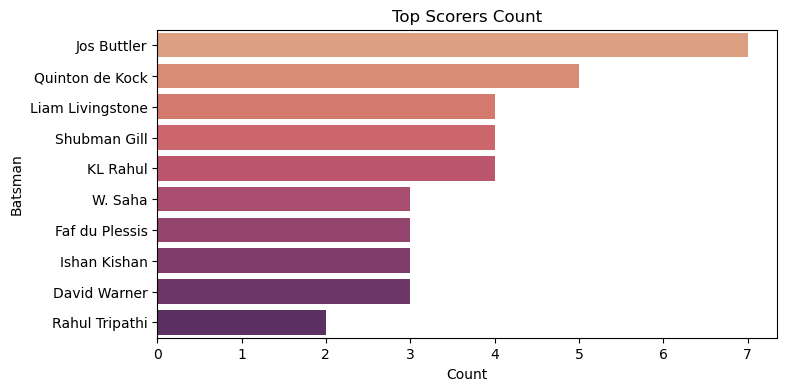

In [10]:
# Top scorers frequency
top_batsmen = ipl_data['top_scorer'].value_counts().head(10)

plt.figure(figsize=(8, 4))
sns.barplot(x=top_batsmen.values, y=top_batsmen.index, palette='flare')
plt.title("Top Scorers Count")
plt.xlabel("Count")
plt.ylabel("Batsman")
plt.show()


### 9. Top Bowlers by Wickets Taken


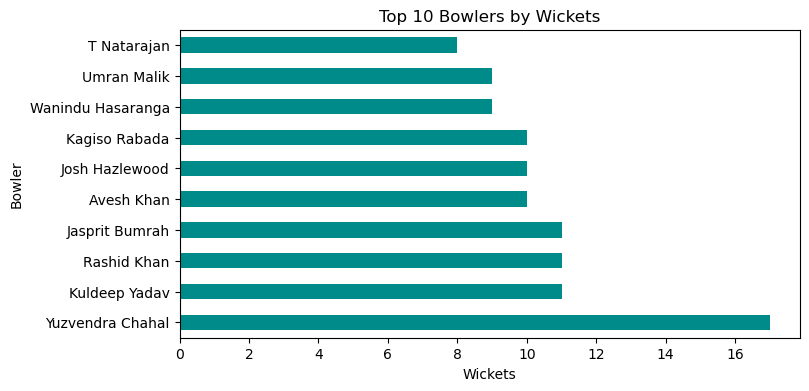

In [11]:
# Extract wickets from bowling figures and plot
bowler_df = ipl_data.copy()
bowler_df['wickets'] = bowler_df['best_bowling_figure'].apply(lambda x: int(str(x).split('--')[0]))
top_bowlers = bowler_df.groupby('best_bowling')['wickets'].sum().sort_values(ascending=False).head(10)

plt.figure(figsize=(8, 4))
top_bowlers.plot(kind='barh', color='darkcyan')
plt.title("Top 10 Bowlers by Wickets")
plt.xlabel("Wickets")
plt.ylabel("Bowler")
plt.show()


### 10. Most Matches Played by Venue


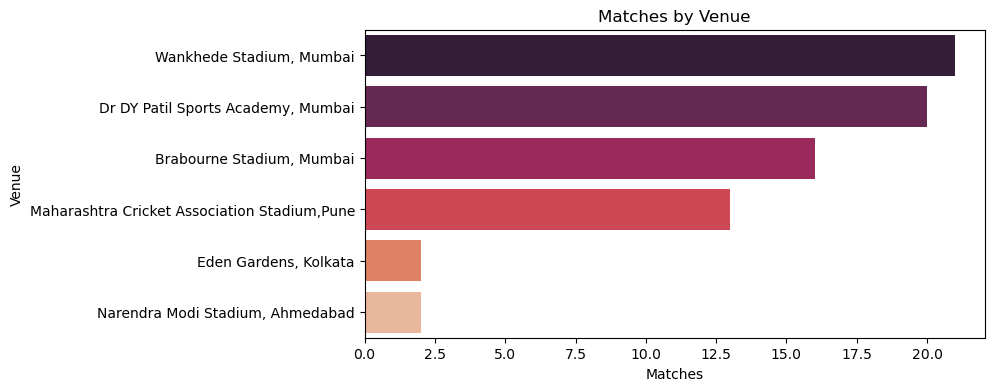

In [12]:
# Matches per venue
venue_data = ipl_data['venue'].value_counts()

plt.figure(figsize=(8, 4))
sns.barplot(x=venue_data.values, y=venue_data.index, palette='rocket')
plt.title("Matches by Venue")
plt.xlabel("Matches")
plt.ylabel("Venue")
plt.show()


### 11. 1st Innings vs 2nd Innings Scores


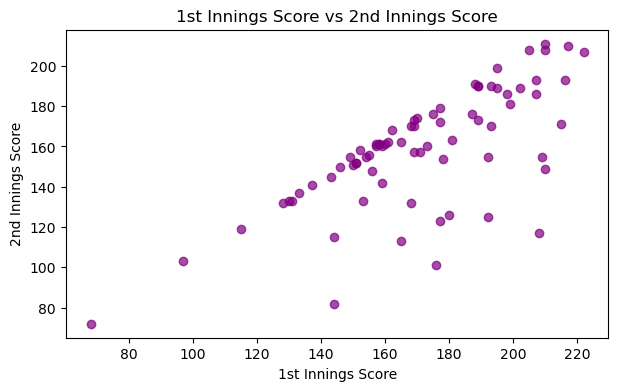

In [13]:
# Scatter plot comparing 1st innings and 2nd innings scores
score_df = ipl_data[['first_ings_score', 'second_ings_score']]

plt.figure(figsize=(7, 4))
plt.scatter(score_df['first_ings_score'], score_df['second_ings_score'], color='purple', alpha=0.7)
plt.title("1st Innings Score vs 2nd Innings Score")
plt.xlabel("1st Innings Score")
plt.ylabel("2nd Innings Score")
plt.show()


### 12. Score Trend Across Matches


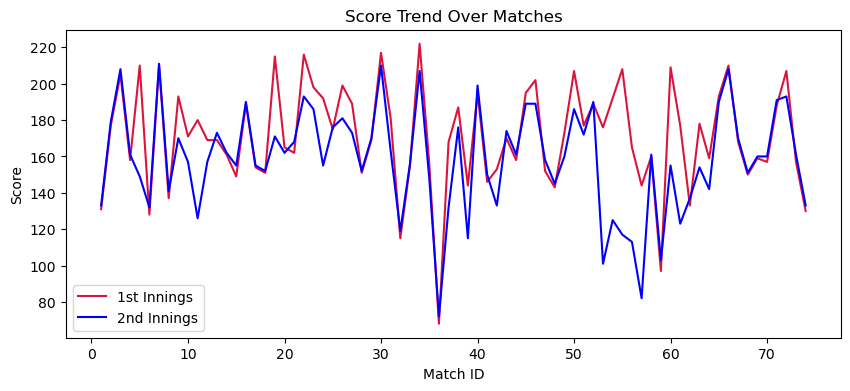

In [14]:
# Line plot of scores across match sequence
trend_df = ipl_data.sort_values('match_id')

plt.figure(figsize=(10, 4))
plt.plot(trend_df['match_id'], trend_df['first_ings_score'], label='1st Innings', color='crimson')
plt.plot(trend_df['match_id'], trend_df['second_ings_score'], label='2nd Innings', color='blue')
plt.title("Score Trend Over Matches")
plt.xlabel("Match ID")
plt.ylabel("Score")
plt.legend()
plt.show()


### Project Completed
Basic visualization analysis completed using Matplotlib and Seaborn.
